# Three distinct data mining methods and evaluations

**Project:** Mining EV Registration Patterns in Washington State  
**Authors:** Afsana Tasnim Juha, Mamata Joshi, Prasanna Thapa

**Research question.** Which combinations of vehicle attributes occur more frequently than expected by chance?

We examine manufacturer, EV type, and five-year model-year group in the sampled Washington EV registrations. Each row represents one vehicle registration. We compare observed co-occurrence with the co-occurrence expected under independence using **lift**.


# 1.Apriori association rule mining

## 1.1 Load the vehicle transactions

Each registration contributes one item from each of three fields. Field names prefix the values so that every item has a clear meaning. The vehicle ID is used only to check that each registration appears once.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

filename = "association_transactions.csv"
folders = (Path("."), Path("data/processed/week09"), Path("upload"))
source = next((folder / filename for folder in folders if (folder / filename).is_file()), None)
if source is None:
    raise FileNotFoundError(f"Place {filename} beside this notebook or in a project data folder.")

attributes = ["Make", "EV_Type", "Year_Group"]
vehicles = pd.read_csv(source, dtype="string", usecols=["DOL Vehicle ID", *attributes])
assert not vehicles.empty
assert not vehicles.isna().any().any()
assert vehicles["DOL Vehicle ID"].is_unique

items = pd.get_dummies(vehicles[attributes], prefix_sep="=", dtype=bool)
assert items.sum(axis=1).eq(len(attributes)).all()
n = len(vehicles)
print(f"Registrations: {n:,}")
print(f"Distinct items: {items.shape[1]}")
print(vehicles[attributes].nunique().to_string())
print("\nEV type counts")
print(vehicles["EV_Type"].value_counts().to_string())

Registrations: 49,873
Distinct items: 56
Make          47
EV_Type        2
Year_Group     7

EV type counts
EV_Type
BEV     40168
PHEV     9705


## 1.2 Find frequent itemsets with Apriori

The methods plan sets a minimum support of **1%** and a maximum of **three items**. Apriori first counts single items and then tests pairs and triples. A candidate can reach the support threshold only if each of its smaller subsets also reaches it. We use this property to skip candidates before counting them.

In [2]:
min_support = 0.01
min_confidence = 0.60
max_length = 3

masks = {column: items[column].to_numpy() for column in sorted(items)}
frequent = {}
previous_level = set()

for length in range(1, max_length + 1):
    current_level = set()
    for candidate in combinations(masks, length):
        if length > 1 and any(
            subset not in previous_level for subset in combinations(candidate, length - 1)
        ):
            continue
        count = int(np.logical_and.reduce([masks[item] for item in candidate]).sum())
        if count / n >= min_support:
            frequent[candidate] = count
            current_level.add(candidate)
    print(f"{length}-item sets meeting minimum support: {len(current_level)}")
    previous_level = current_level

1-item sets meeting minimum support: 23
2-item sets meeting minimum support: 52
3-item sets meeting minimum support: 19


## 1.3 Build and evaluate association rules

A rule has a left side, **A**, and a right side, **B**. We report the number of registrations containing both sides along with three measures.

| Measure | Calculation | Meaning |
|---|---|---|
| Support | Count containing both sides ÷ total registrations | How common the full combination is |
| Confidence | Count containing both sides ÷ count containing A | How often B occurs when A occurs |
| Lift | Confidence ÷ overall proportion containing B | How much more often B occurs with A than expected under independence |

We keep rules with confidence of **at least 60%** and lift **above 1**. We also show the expected count under independence. A rule and its reverse have the same support and lift, while confidence can differ. The chart uses one direction per pair of sides to avoid displaying the same association twice.

In [3]:
records = []
for itemset, observed in frequent.items():
    for size in range(1, len(itemset)):
        for left in combinations(itemset, size):
            right = tuple(item for item in itemset if item not in left)
            left_count, right_count = frequent[left], frequent[right]
            confidence = observed / left_count
            expected = left_count * right_count / n
            lift = observed / expected
            if confidence >= min_confidence and lift > 1:
                records.append({
                    "antecedent": " + ".join(left),
                    "consequent": " + ".join(right),
                    "observed": observed,
                    "expected": expected,
                    "support": observed / n,
                    "confidence": confidence,
                    "lift": lift,
                    "association": tuple(sorted((left, right))),
                })

rules = pd.DataFrame(records).sort_values(
    ["lift", "observed", "confidence", "antecedent", "consequent"],
    ascending=[False, False, False, True, True],
).reset_index(drop=True)
assert rules["support"].ge(min_support).all()
assert rules["confidence"].ge(min_confidence).all()
assert rules["observed"].gt(rules["expected"]).all()

distinct_rules = rules.drop_duplicates("association")
print(f"Qualifying directional rules: {len(rules)}")
print(f"Associations after combining reverse directions: {len(distinct_rules)}")
print(rules.drop(columns="association").head(12).to_string(
    index=False,
    formatters={"expected": "{:.1f}".format, "support": "{:.2%}".format,
                "confidence": "{:.2%}".format, "lift": "{:.3f}".format},
))

Qualifying directional rules: 45
Associations after combining reverse directions: 45
                        antecedent                          consequent  observed expected support confidence   lift
EV_Type=BEV + Year_Group=2010-2014                         Make=NISSAN       527     45.6   1.06%     62.89% 11.552
                         Make=JEEP EV_Type=PHEV + Year_Group=2020-2024       935    102.7   1.87%     89.73%  9.101
                     Make=CHRYSLER                        EV_Type=PHEV       612    119.1   1.23%    100.00%  5.139
  Make=JEEP + Year_Group=2020-2024                        EV_Type=PHEV       935    184.5   1.87%     98.63%  5.068
                         Make=JEEP                        EV_Type=PHEV      1002    202.8   2.01%     96.16%  4.942
Make=TOYOTA + Year_Group=2020-2024                        EV_Type=PHEV       865    211.5   1.73%     79.58%  4.089
                       Make=TOYOTA                        EV_Type=PHEV      1767    444.8   3.54%     7

## 1.4 Compare the strongest associations

The dashed line shows lift of 1, the value expected under independence. Read the chart alongside the support and observed counts in the table. A high lift can come from a relatively small group.

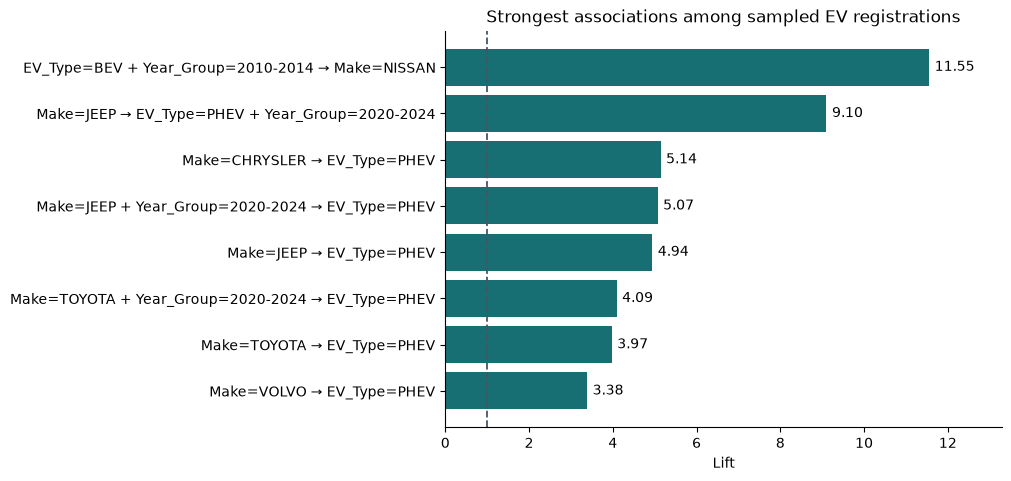

In [4]:
plot_data = distinct_rules.head(8).iloc[::-1]
labels = plot_data["antecedent"] + " → " + plot_data["consequent"]

fig, ax = plt.subplots(figsize=(10, 4.7), layout="constrained")
bars = ax.barh(labels, plot_data["lift"], color="#176f73")
ax.axvline(1, color="#465563", linestyle="--", linewidth=1.3)
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set(xlabel="Lift", title="Strongest associations among sampled EV registrations",
       xlim=(0, plot_data["lift"].max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 1.5 Findings and limitations

- **Highest lift.** For `EV_Type=BEV + Year_Group=2010-2014 → Make=NISSAN`, 527 registrations matched both sides, compared with 45.6 expected under independence. The lift was 11.55. The rule covered 1.06% of the sample, and 62.9% of registrations on the left side also matched the right side.
- **Highest support among retained rules.** For `Year_Group=2020-2024 → EV_Type=BEV`, 24,095 registrations matched both sides (48.31% of the sample). Confidence was 83.1% and lift was 1.03. This shows how a widely occurring combination can have a smaller lift than the highest-ranked rule.

These associations describe the sampled registrations. Lift compares observed frequency with an independence benchmark. We did not run significance tests or assess generalization beyond this sample. The minimum support can exclude patterns involving rare manufacturers or older model-year groups. Five-year groups can also hide differences between individual model years.

